## Practice: Basic Artificial Neural Networks
Credits: this notebook belongs to [Practical DL](https://docs.google.com/forms/d/e/1FAIpQLScvrVtuwrHSlxWqHnLt1V-_7h2eON_mlRR6MUb3xEe5x9LuoA/viewform?usp=sf_link) course by Yandex School of Data Analysis.

We will start working with neural networks on the practice session. Your homework will be to finish the implementation of the layers.

Our goal is simple, yet an actual implementation may take some time :). We are going to write an Artificial Neural Network (almost) from scratch. The software design was heavily inspired by [PyTorch](http://pytorch.org) which is the main framework of our course

Speaking about the homework (once again, it will be really similar to this seminar), it requires sending **multiple** files, please do not forget to include all the files when sending to TA. The list of files:
- This notebook
- modules.ipynb with all blocks implemented (except maybe `Conv2d` and `MaxPool2d` layers implementation which are part of 'advanced' version of this homework)

In [46]:
%matplotlib inline
from time import time, sleep
import numpy as np
import matplotlib.pyplot as plt
from IPython import display

# Framework

Implement everything in `modules.ipynb`. Read all the comments thoughtfully to ease the pain. Please try not to change the prototypes.

Do not forget, that each module should return **AND** store `output` and `gradInput`.

The typical assumption is that `module.backward` is always executed after `module.forward`,
so `output` is stored, this would be useful for `SoftMax`.

### Tech note
Prefer using `np.multiply`, `np.add`, `np.divide`, `np.subtract` instead of `*`,`+`,`/`,`-` for better memory handling.

Example: suppose you allocated a variable

```
a = np.zeros(...)
```
So, instead of
```
a = b + c  # will be reallocated, GC needed to free
```
You can use:
```
np.add(b,c,out = a) # puts result in `a`
```

In [47]:
# (re-)load layers
%run modules.ipynb

<>:3: SyntaxWarning: invalid escape sequence '\g'
/tmp/ipykernel_928/3092293347.py:3: SyntaxWarning: invalid escape sequence '\g'
  Implements linear transform of input y = \gamma * x + \beta


# Toy example

Use this example to debug your code, start with logistic regression and then test other layers. You do not need to change anything here. This code is provided for you to test the layers. Also it is easy to use this code in MNIST task.

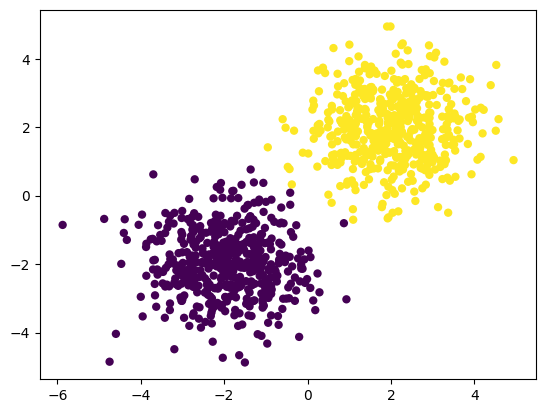

In [48]:
# Generate some data
N = 500

X1 = np.random.randn(N,2) + np.array([2,2])
X2 = np.random.randn(N,2) + np.array([-2,-2])

Y = np.concatenate([np.ones(N),np.zeros(N)])[:,None]
Y = np.hstack([Y, 1-Y])

X = np.vstack([X1,X2])
plt.scatter(X[:,0],X[:,1], c = Y[:,0], edgecolors= 'none')

Define a **logistic regression** for debugging.

In [49]:
net = Sequential()
net.add(Linear(2, 2))
net.add(LogSoftMax())

criterion = ClassNLLCriterion()

print(net)

# Test something like that then

# net = Sequential()
# net.add(Linear(2, 4))
# net.add(ReLU())
# net.add(Linear(4, 2))
# net.add(LogSoftMax())

Linear 2 -> 2
LogSoftMax



Start with batch_size = 1000 to make sure every step lowers the loss, then try stochastic version.

In [50]:
# Iptimizer params
optimizer_config = {'learning_rate' : 1e-1, 'momentum': 0.9}
optimizer_state = {}

# Looping params
n_epoch = 20
batch_size = 128

In [51]:
# batch generator
def get_batches(dataset, batch_size):
    X, Y = dataset
    n_samples = X.shape[0]

    # Shuffle at the start of epoch
    indices = np.arange(n_samples)
    np.random.shuffle(indices)

    for start in range(0, n_samples, batch_size):
        end = min(start + batch_size, n_samples)

        batch_idx = indices[start:end]

        yield X[batch_idx], Y[batch_idx]

### Train

Basic training loop. Examine it.

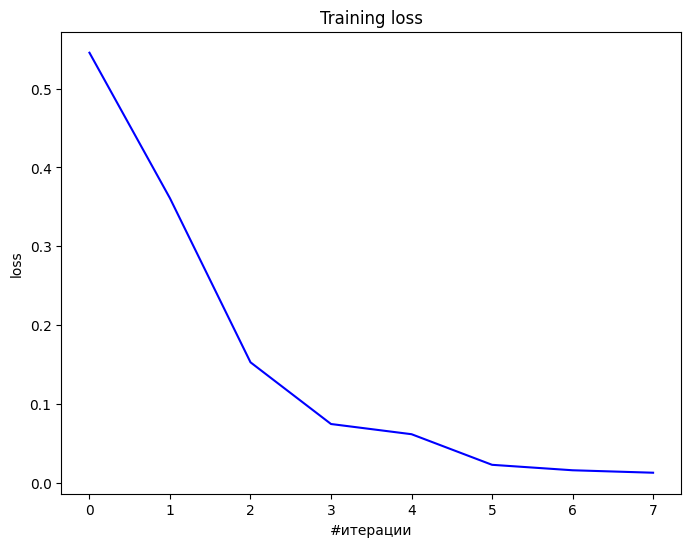

Текущий loss: 0.012643


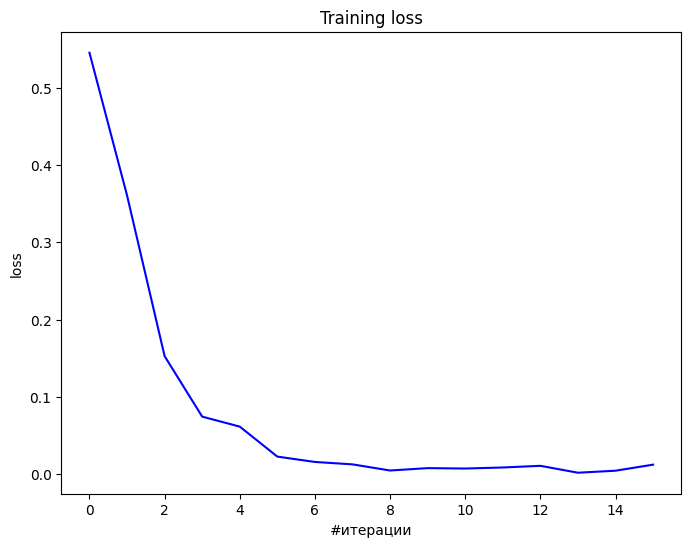

Текущий loss: 0.012268


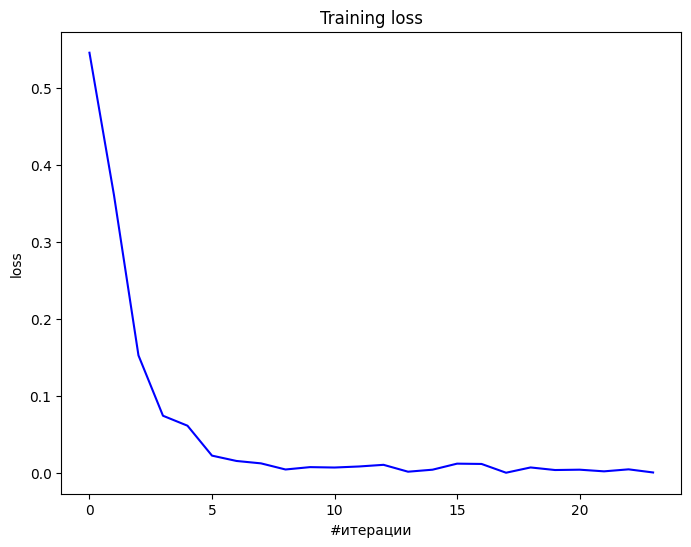

Текущий loss: 0.000819


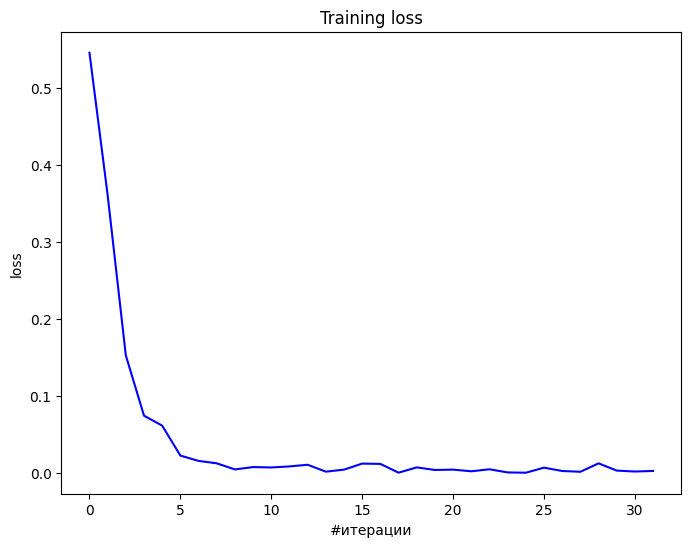

Текущий loss: 0.002753


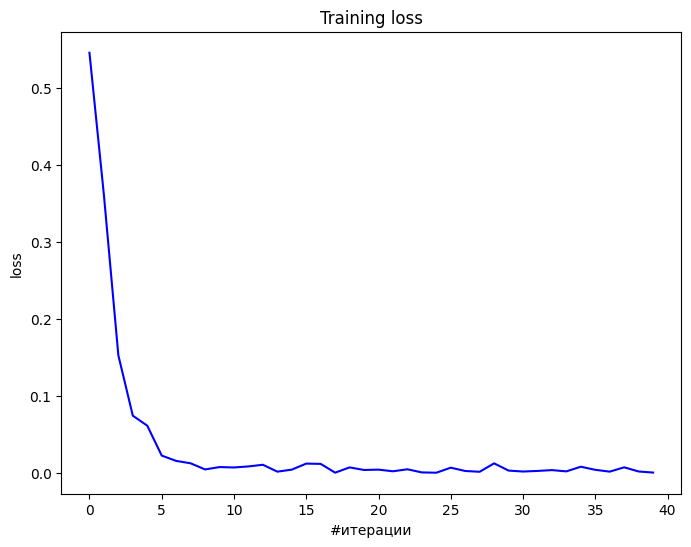

Текущий loss: 0.000617


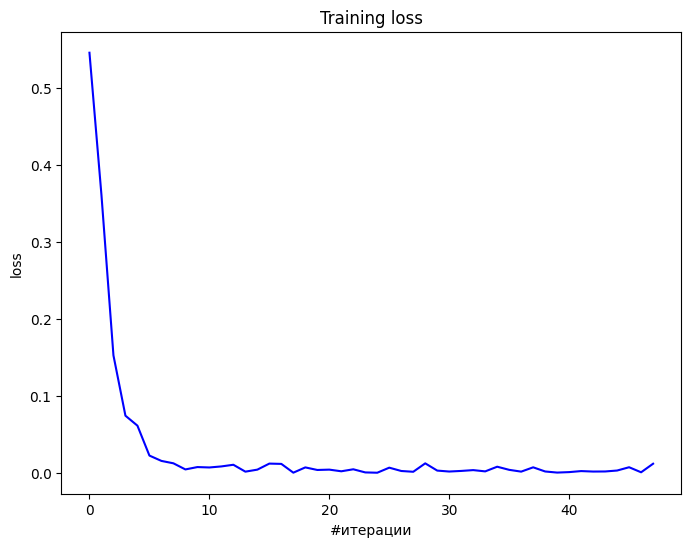

Текущий loss: 0.012106


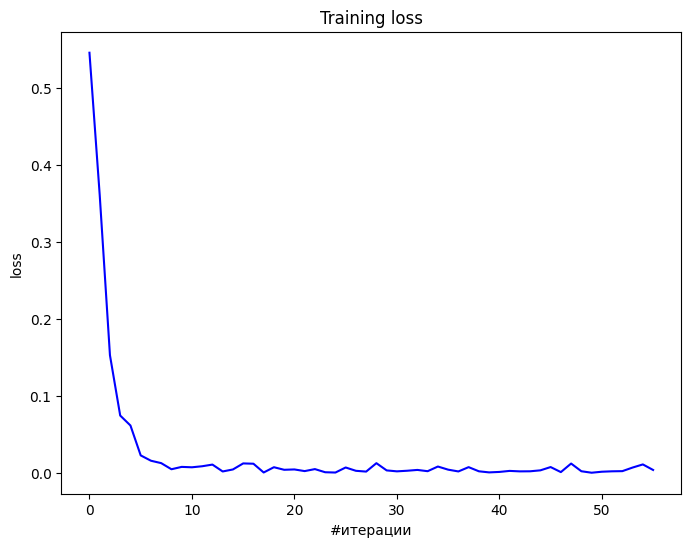

Текущий loss: 0.003774


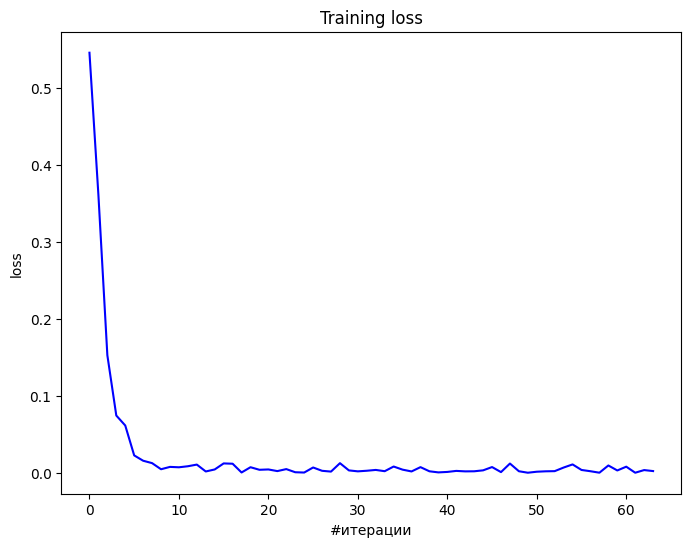

Текущий loss: 0.002325


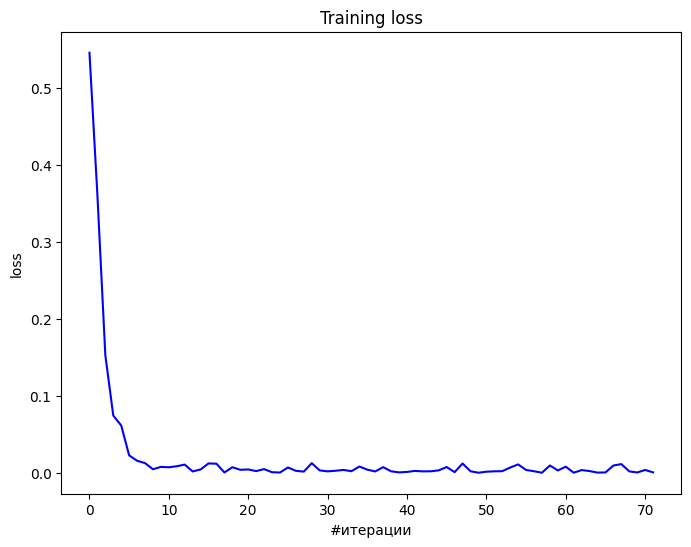

Текущий loss: 0.000642


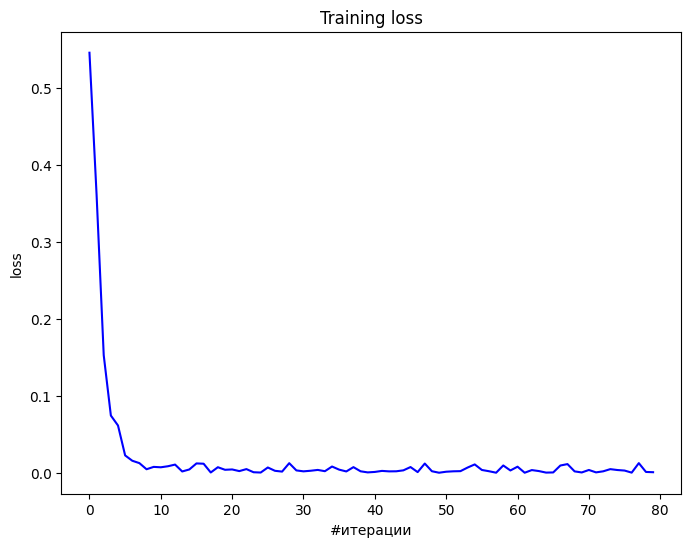

Текущий loss: 0.000848


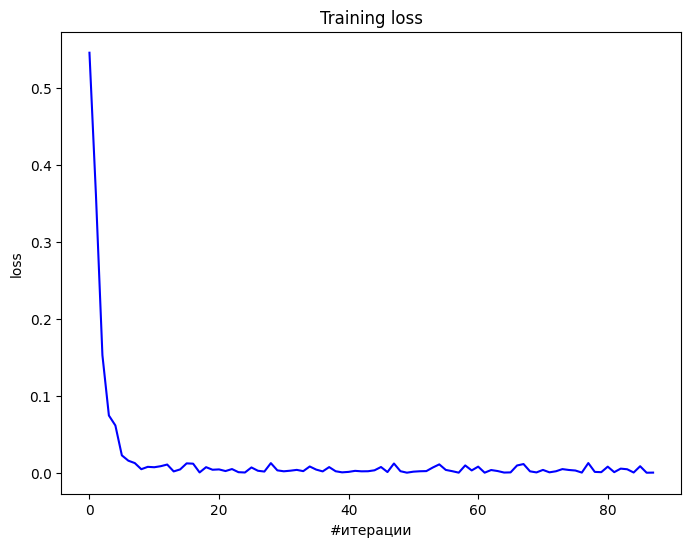

Текущий loss: 0.000277


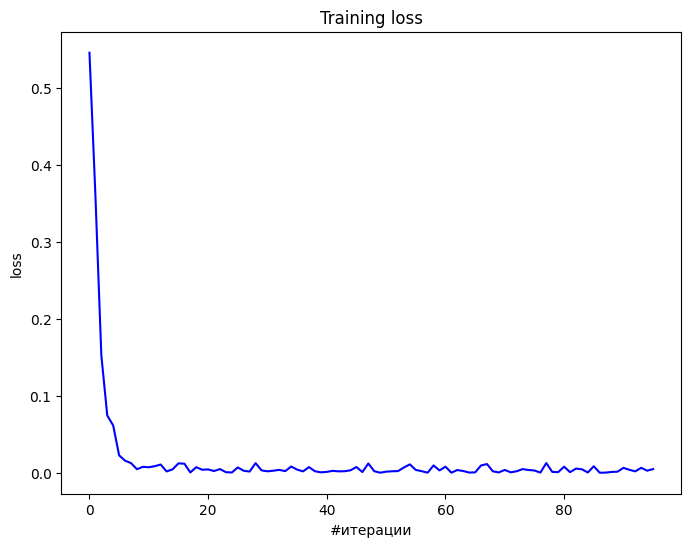

Текущий loss: 0.004856


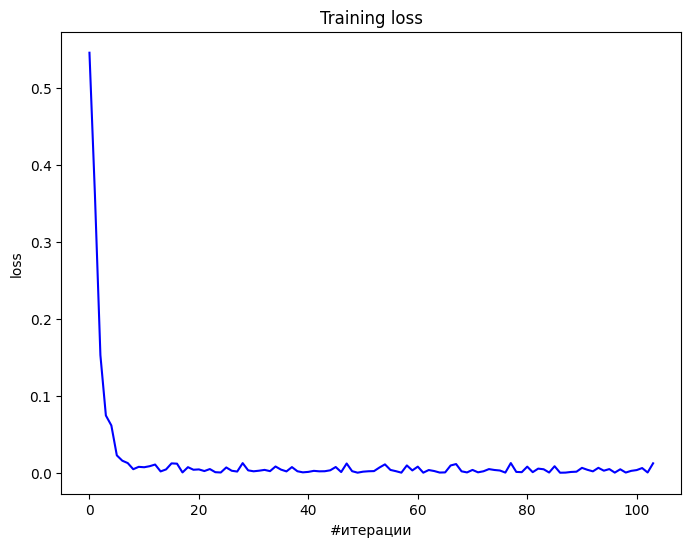

Текущий loss: 0.012354


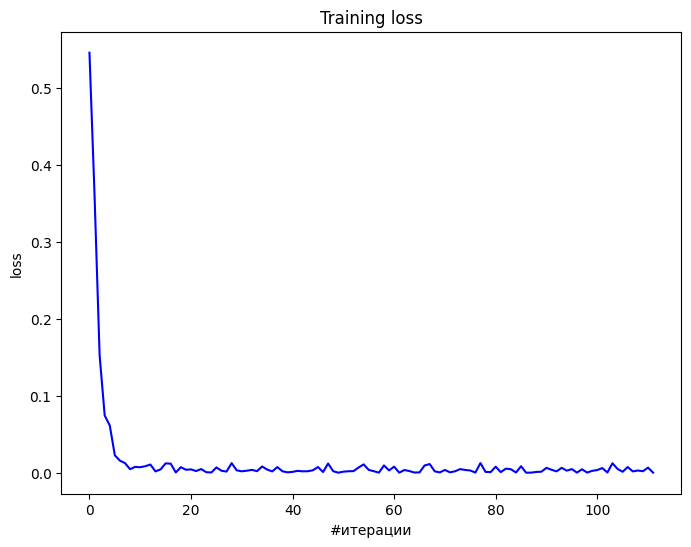

Текущий loss: 0.000263


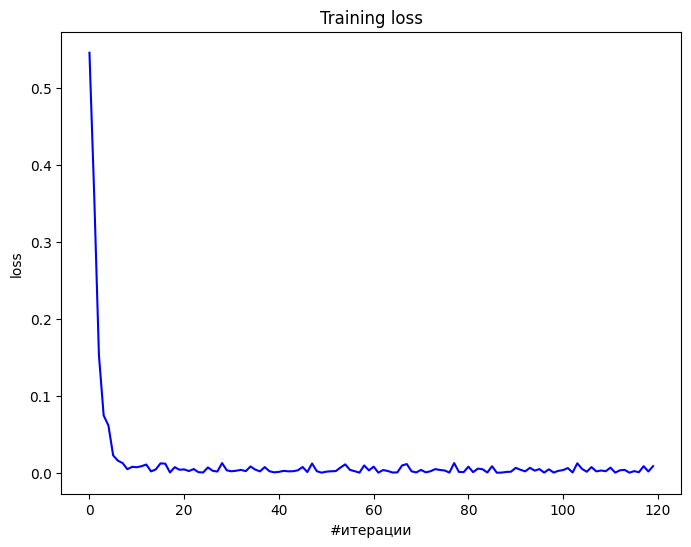

Текущий loss: 0.008719


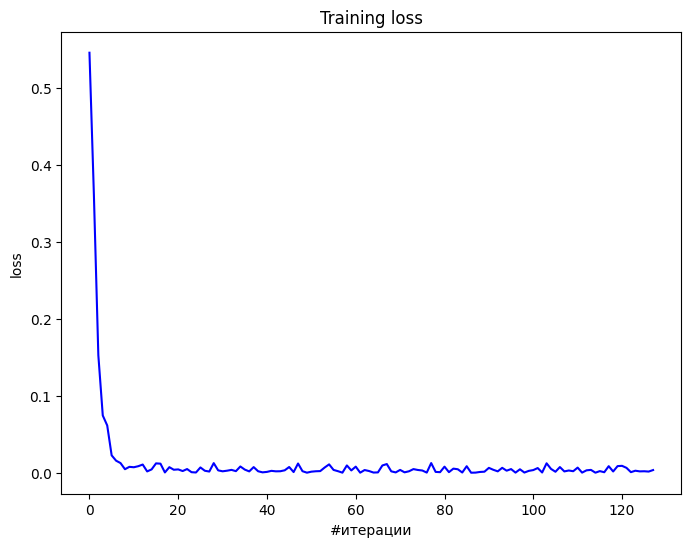

Текущий loss: 0.003593


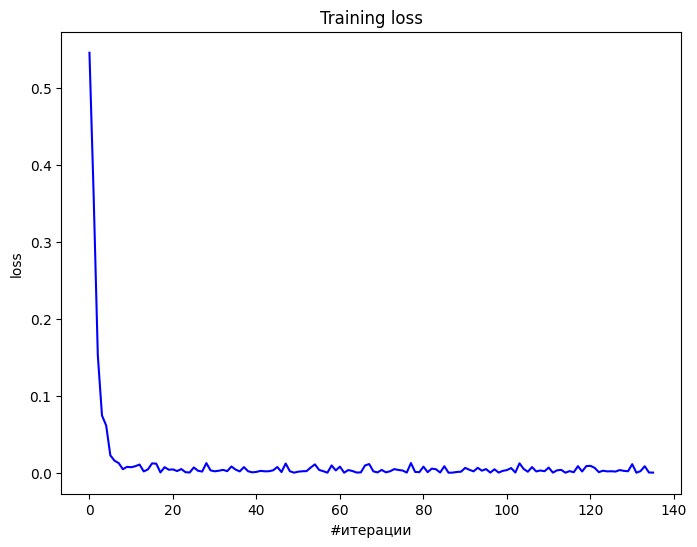

Текущий loss: 0.000262


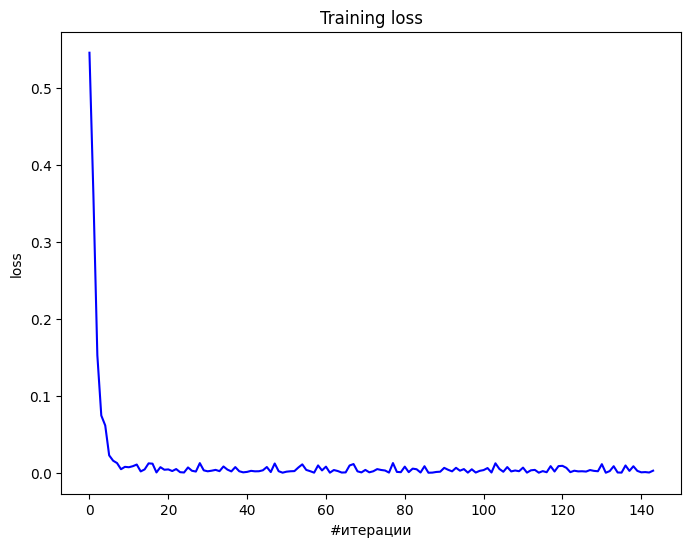

Текущий loss: 0.002803


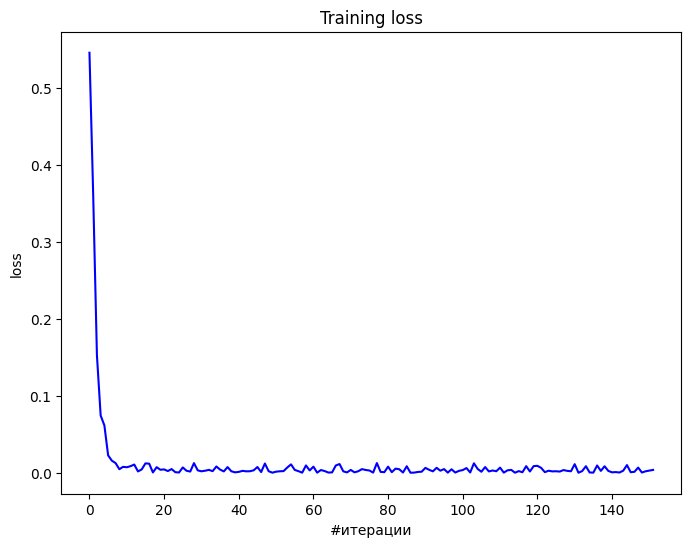

Текущий loss: 0.003788


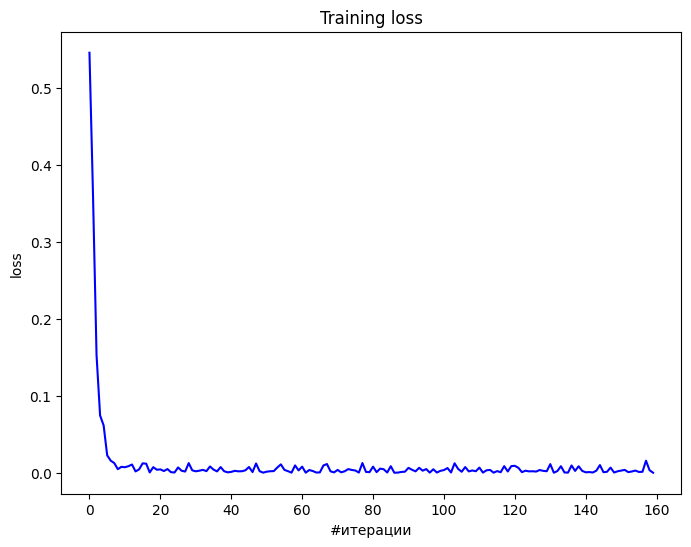

Текущий loss: 0.000115


In [52]:
loss_history = []

for i in range(n_epoch):
    for x_batch, y_batch in get_batches((X, Y), batch_size):
        net.zeroGradParameters()
        predictions = net.forward(x_batch)
        loss = criterion.forward(predictions, y_batch)
        dp = criterion.backward(predictions, y_batch)
        net.backward(x_batch, dp)
        sgd_momentum(net.getParameters(),
                     net.getGradParameters(),
                     optimizer_config,
                     optimizer_state)
        loss_history.append(loss)

    plt.figure(figsize=(8, 6))
    plt.title("Training loss")
    plt.xlabel("#итерации")
    plt.ylabel("loss")
    plt.plot(loss_history, 'b')
    plt.show()

    print('Текущий loss: %f' % loss)

# Digit classification

We are using old good [MNIST](http://yann.lecun.com/exdb/mnist/) as our dataset. It can be downloaded with the following file.

In [53]:
!wget https://raw.githubusercontent.com/girafe-ai/ml-course/23f_basic/homeworks/hw08_nn_from_scratch/mnist.py -nc

File ‘mnist.py’ already there; not retrieving.



In [54]:
%run mnist.py

<Figure size 640x480 with 0 Axes>

In [55]:
import mnist
import os
import urllib

base_url = "https://ossci-datasets.s3.amazonaws.com/mnist/"

files = [
    "train-images-idx3-ubyte.gz",
    "train-labels-idx1-ubyte.gz",
    "t10k-images-idx3-ubyte.gz",
    "t10k-labels-idx1-ubyte.gz"
]

for filename in files:
    if not os.path.exists(filename):
        print("Downloading", filename)
        urllib.request.urlretrieve(base_url + filename, filename)

X_train, y_train, X_val, y_val, X_test, y_test = mnist.load_dataset()

One-hot encode the labels first.

In [56]:
# Your code goes here. ################################################
def one_hot(labels, n_classes=10):
    labels = np.asarray(labels).astype(int).ravel()
    result = np.zeros((labels.shape[0], n_classes), dtype=np.float32)
    result[np.arange(labels.shape[0]), labels] = 1.0

    return result

X_train = X_train.reshape(X_train.shape[0], -1).astype(np.float32) / 255.0
X_val = X_val.reshape(X_val.shape[0], -1).astype(np.float32) / 255.0
X_test = X_test.reshape(X_test.shape[0], -1).astype(np.float32) / 255.0

Y_train = one_hot(y_train)
Y_val = one_hot(y_val)
Y_test = one_hot(y_test)

print("Train:", X_train.shape, Y_train.shape)
print("Val:", X_val.shape, Y_val.shape)
print("Test:", X_test.shape, Y_test.shape)

Train: (50000, 784) (50000, 10)
Val: (10000, 784) (10000, 10)
Test: (10000, 784) (10000, 10)


- **Compare** `ReLU`, `ELU`, `LeakyReLU`, `SoftPlus` activation functions.
You would better pick the best optimizer params for each of them, but it is overkill for now. Use an architecture of your choice for the comparison.
- **Try** inserting `BatchNormalization` (folowed by `ChannelwiseScaling`) between `Linear` module and activation functions.
- Plot the losses both from activation functions comparison and `BatchNormalization` comparison on one plot. Please find a scale (log?) when the lines are distinguishable, do not forget about naming the axes, the plot should be goodlooking.
- Plot the losses for two networks: one trained by momentum_sgd, another one trained by Adam. Which one performs better?
- Hint: good logloss for MNIST should be around 0.5.


Activation: ReLU
Эпоха 1/4 - train loss: 2.2877 - validation loss: 2.2574
Эпоха 2/4 - train loss: 2.1862 - validation loss: 2.0961
Эпоха 3/4 - train loss: 1.9680 - validation loss: 1.8417
Эпоха 4/4 - train loss: 1.7032 - validation loss: 1.5849

Activation: ELU
Эпоха 1/4 - train loss: 2.2740 - validation loss: 2.2220
Эпоха 2/4 - train loss: 2.0915 - validation loss: 1.9288
Эпоха 3/4 - train loss: 1.7256 - validation loss: 1.5390
Эпоха 4/4 - train loss: 1.3693 - validation loss: 1.2343

Activation: LeakyReLU
Эпоха 1/4 - train loss: 2.2852 - validation loss: 2.2455
Эпоха 2/4 - train loss: 2.1346 - validation loss: 1.9858
Эпоха 3/4 - train loss: 1.7833 - validation loss: 1.5973
Эпоха 4/4 - train loss: 1.4304 - validation loss: 1.2931

Activation: SoftPlus
Эпоха 1/4 - train loss: 2.3016 - validation loss: 2.2887
Эпоха 2/4 - train loss: 2.2839 - validation loss: 2.2722
Эпоха 3/4 - train loss: 2.2648 - validation loss: 2.2531
Эпоха 4/4 - train loss: 2.2396 - validation loss: 2.2262

Без Bat

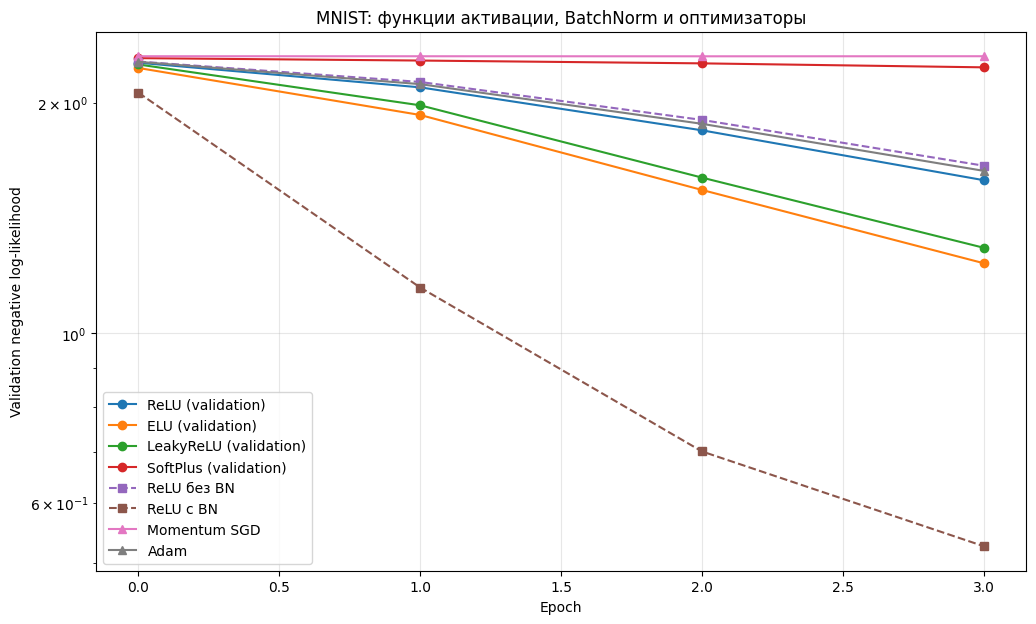

Accuracy: SGD = 0.1083, Adam = 0.5760


In [57]:
# Your code goes here. ################################################
def make_network(activation, use_bn=False, hidden_size=128, dropout=0.0):
    net = Sequential()
    net.add(Linear(X_train.shape[1], hidden_size))

    if use_bn:
        net.add(BatchNormalization(alpha=0.9))
        net.add(ChannelwiseScaling(hidden_size))
    net.add(activation)

    if dropout:
        net.add(Dropout(dropout))
    net.add(Linear(hidden_size, 10))
    net.add(LogSoftMax())

    return net


def accuracy(net, x, labels):
    net.evaluate()
    predicted = np.argmax(net.forward(x), axis=1)
    net.train()

    return np.mean(predicted == np.asarray(labels).ravel())


def train_network(net, x, y, x_val, y_val, epochs=4, batch_size=128, optimizer="adam", learning_rate=1e-3):
    criterion = ClassNLLCriterion()
    history = []
    state = {}

    if optimizer == "adam":
        config = {"learning_rate": learning_rate, "beta1": 0.9, "beta2": 0.999, "epsilon": 1e-8}
        update = adam_optimizer
    else:
        config = {"learning_rate": learning_rate, "momentum": 0.9}
        update = sgd_momentum

    for epoch in range(epochs):
        net.train()
        epoch_losses = []

        for xb, yb in get_batches((x, y), batch_size):
            net.zeroGradParameters()
            pred = net.forward(xb)
            loss = criterion.forward(pred, yb)
            grad = criterion.backward(pred, yb)
            net.backward(xb, grad)
            update(net.getParameters(), net.getGradParameters(), config, state)
            epoch_losses.append(loss)

        net.evaluate()
        val_loss = criterion.forward(net.forward(x_val), y_val)
        history.append((float(np.mean(epoch_losses)), float(val_loss)))
        print("Эпоха %d/%d - train loss: %.4f - validation loss: %.4f" %
              (epoch + 1, epochs, history[-1][0], history[-1][1]))
    net.train()

    return history

rng = np.random.RandomState(42)
experiment_ids = rng.permutation(len(X_train))[:12000]
validation_ids = np.arange(min(3000, len(X_val)))
X_exp, Y_exp = X_train[experiment_ids], Y_train[experiment_ids]
X_exp_val, Y_exp_val = X_val[validation_ids], Y_val[validation_ids]
y_exp_val = np.asarray(y_val).ravel()[validation_ids]

activation_factories = {
    "ReLU": ReLU,
    "ELU": ELU,
    "LeakyReLU": LeakyReLU,
    "SoftPlus": SoftPlus
}
activation_histories = {}

for name, factory in activation_factories.items():
    print("\nActivation:", name)
    model = make_network(factory())
    activation_histories[name] = train_network(
        model, X_exp, Y_exp, X_exp_val, Y_exp_val,
        epochs=4, optimizer="adam", learning_rate=1e-3
    )

print("\nБез BatchNormalization")
plain_model = make_network(ReLU())
plain_history = train_network(
    plain_model, X_exp, Y_exp, X_exp_val, Y_exp_val,
    epochs=4, optimizer="adam", learning_rate=1e-3
)

print("\nС BatchNormalization")
bn_model = make_network(ReLU(), use_bn=True)
bn_history = train_network(
    bn_model, X_exp, Y_exp, X_exp_val, Y_exp_val,
    epochs=4, optimizer="adam", learning_rate=1e-3
)

print("\nMomentum SGD")
sgd_model = make_network(ReLU())
sgd_history = train_network(
    sgd_model, X_exp, Y_exp, X_exp_val, Y_exp_val,
    epochs=4, optimizer="sgd", learning_rate=0.03
)

print("\nAdam")
adam_model = make_network(ReLU())
adam_history = train_network(
    adam_model, X_exp, Y_exp, X_exp_val, Y_exp_val,
    epochs=4, optimizer="adam", learning_rate=1e-3
)

plt.figure(figsize=(12, 7))

for name, history in activation_histories.items():
    plt.plot([h[1] for h in history], marker="o", label=name + " (validation)")
plt.plot([h[1] for h in plain_history], marker="s", linestyle="--",
         label="ReLU без BN")
plt.plot([h[1] for h in bn_history], marker="s", linestyle="--",
         label="ReLU с BN")
plt.plot([h[1] for h in sgd_history], marker="^", label="Momentum SGD")
plt.plot([h[1] for h in adam_history], marker="^", label="Adam")
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Validation negative log-likelihood")
plt.title("MNIST: функции активации, BatchNorm и оптимизаторы")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

print("Accuracy: SGD = %.4f, Adam = %.4f" %
      (accuracy(sgd_model, X_exp_val, y_exp_val),
       accuracy(adam_model, X_exp_val, y_exp_val)))

Write your personal opinion on the activation functions, think about computation times too. Does `BatchNormalization` help?

In [58]:
# Your answer goes here. ################################################

# ReLU самая простая функция активации, т.е. нужно только взять максимум между значением входа и нулём.
# LeakyReLU не сложнее, но сохраняет небольшой градиент для отрицательных входных значений.
# ELU и SoftPlus используют экспоненту и логарифм следовательно вычислительно обходятся дороже. ELU может выдавать отрицательные значения,
# а SoftPlus является гладким приближением ReLU.
#
# Выбирать лучшую функцию активации стоит по ошибке и точности на валидации, а не только по графику обучения.
# В этом эксперименте результаты могут быть близкими, а конкретный порядок зависит от
# начальной инициализации весов и скорости обучения.
#
# BatchNormalization может сделать обучение стабильнее за счёт нормализации скрытых активаций,
# но она не обязательно улучшает качество на валидации в каждом запуске: эффект зависит от размера батча и архитектуры модели.
# ChannelwiseScaling добавляет обучаемые параметры масштаба и сдвига после нормализации.
#
# Adam быстрее сходится и требует меньше подбора параметров.
# Momentum SGD тоже может показать сопоставимый результат, если правильно подобрать скорость обучения.
# Для сравнения нужно смотреть на фактические значения ошибки и точности на валидации полученные в этом запуске.

**Finally**, use all your knowledge to build a super cool model on this dataset. Use **dropout** to prevent overfitting, play with **learning rate decay**. You can use **data augmentation** such as rotations, translations to boost your score. Use your knowledge and imagination to train a model. Don't forget to call `training()` and `evaluate()` methods to set desired behaviour of `BatchNormalization` and `Dropout` layers.

Epoch  1/12 | lr 0.00100 | train loss 1.3581 | val loss 0.4689 | val accuracy 0.8624
Epoch  2/12 | lr 0.00100 | train loss 0.4413 | val loss 0.3104 | val accuracy 0.9066
Epoch  3/12 | lr 0.00100 | train loss 0.3480 | val loss 0.2574 | val accuracy 0.9227
Epoch  4/12 | lr 0.00100 | train loss 0.2952 | val loss 0.2242 | val accuracy 0.9320
Epoch  5/12 | lr 0.00050 | train loss 0.2627 | val loss 0.2086 | val accuracy 0.9374
Epoch  6/12 | lr 0.00050 | train loss 0.2454 | val loss 0.1960 | val accuracy 0.9411
Epoch  7/12 | lr 0.00050 | train loss 0.2302 | val loss 0.1826 | val accuracy 0.9466
Epoch  8/12 | lr 0.00050 | train loss 0.2161 | val loss 0.1744 | val accuracy 0.9475
Epoch  9/12 | lr 0.00025 | train loss 0.2024 | val loss 0.1680 | val accuracy 0.9509
Epoch 10/12 | lr 0.00025 | train loss 0.1968 | val loss 0.1633 | val accuracy 0.9523
Epoch 11/12 | lr 0.00025 | train loss 0.1902 | val loss 0.1611 | val accuracy 0.9521
Epoch 12/12 | lr 0.00025 | train loss 0.1862 | val loss 0.1565 | 

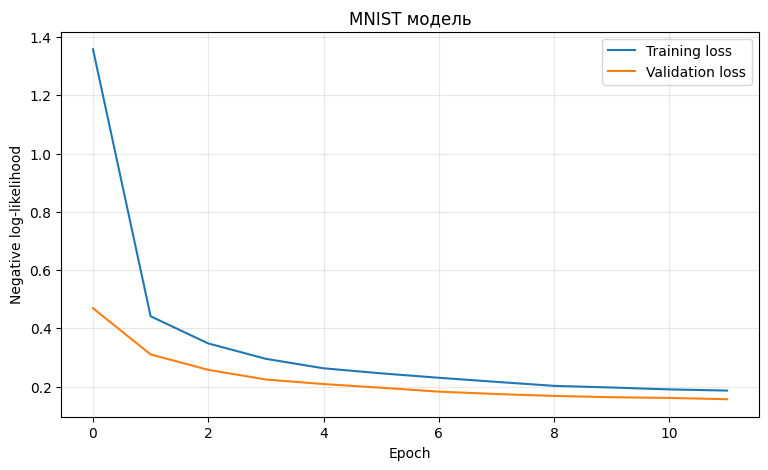

In [59]:
# Your code goes here. ################################################
rng = np.random.RandomState(7)
final_ids = rng.permutation(len(X_train))[:30000]
X_final = X_train[final_ids]
Y_final = Y_train[final_ids]

final_net = Sequential()
final_net.add(Linear(X_train.shape[1], 256))
final_net.add(BatchNormalization(alpha=0.9))
final_net.add(ChannelwiseScaling(256))
final_net.add(ReLU())
final_net.add(Dropout(0.15))
final_net.add(Linear(256, 128))
final_net.add(ReLU())
final_net.add(Dropout(0.10))
final_net.add(Linear(128, 10))
final_net.add(LogSoftMax())

criterion = ClassNLLCriterion()
optimizer_state = {}
base_lr = 1e-3
batch_size = 128
n_epoch = 12
final_history = []

for epoch in range(n_epoch):
    learning_rate = base_lr * (0.5 ** (epoch // 4))
    optimizer_config = {
        "learning_rate": learning_rate,
        "beta1": 0.9,
        "beta2": 0.999,
        "epsilon": 1e-8
    }
    final_net.train()
    batch_losses = []

    for x_batch, y_batch in get_batches((X_final, Y_final), batch_size):
        final_net.zeroGradParameters()
        predictions = final_net.forward(x_batch)
        loss = criterion.forward(predictions, y_batch)
        grad = criterion.backward(predictions, y_batch)
        final_net.backward(x_batch, grad)
        adam_optimizer(final_net.getParameters(),
                       final_net.getGradParameters(),
                       optimizer_config, optimizer_state)
        batch_losses.append(loss)

    final_net.evaluate()
    val_loss = criterion.forward(final_net.forward(X_val), Y_val)
    val_acc = np.mean(np.argmax(final_net.output, axis=1) == np.asarray(y_val).ravel())
    final_history.append((np.mean(batch_losses), val_loss, val_acc))
    print("Epoch %2d/%d | lr %.5f | train loss %.4f | val loss %.4f | val accuracy %.4f" %
          (epoch + 1, n_epoch, learning_rate, np.mean(batch_losses), val_loss, val_acc))

plt.figure(figsize=(9, 5))
plt.plot([x[0] for x in final_history], label="Training loss")
plt.plot([x[1] for x in final_history], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Negative log-likelihood")
plt.title("MNIST модель")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

Print here your accuracy on test set. It should be around 90%.

In [60]:
# Your answer goes here. ################################################
final_net.evaluate()
test_predictions = np.argmax(final_net.forward(X_test), axis=1)
test_accuracy = np.mean(test_predictions == np.asarray(y_test).ravel())

print("Test accuracy: %.2f%%" % (100 * test_accuracy))

Test accuracy: 94.91%


### Comparing with PyTorch implementation
The last (and maybe the easiest step after compared to the previous tasks: build a network with the same architecture as above now with PyTorch.

You can refer to the `week0_09` or `Lab3_part2` notebooks for hints.

__Good Luck!__

Device: cpu
Epoch  1/12 | train loss 0.4724 | val loss 0.1982 | val accuracy 0.9421
Epoch  2/12 | train loss 0.1783 | val loss 0.2154 | val accuracy 0.9340
Epoch  3/12 | train loss 0.1217 | val loss 0.1342 | val accuracy 0.9606
Epoch  4/12 | train loss 0.0938 | val loss 0.1191 | val accuracy 0.9627
Epoch  5/12 | train loss 0.0651 | val loss 0.0938 | val accuracy 0.9726
Epoch  6/12 | train loss 0.0550 | val loss 0.1066 | val accuracy 0.9689
Epoch  7/12 | train loss 0.0474 | val loss 0.0934 | val accuracy 0.9744
Epoch  8/12 | train loss 0.0406 | val loss 0.0918 | val accuracy 0.9744
Epoch  9/12 | train loss 0.0345 | val loss 0.0833 | val accuracy 0.9763
Epoch 10/12 | train loss 0.0302 | val loss 0.0828 | val accuracy 0.9767
Epoch 11/12 | train loss 0.0273 | val loss 0.0812 | val accuracy 0.9772
Epoch 12/12 | train loss 0.0260 | val loss 0.0807 | val accuracy 0.9772
PyTorch test accuracy: 97.66%


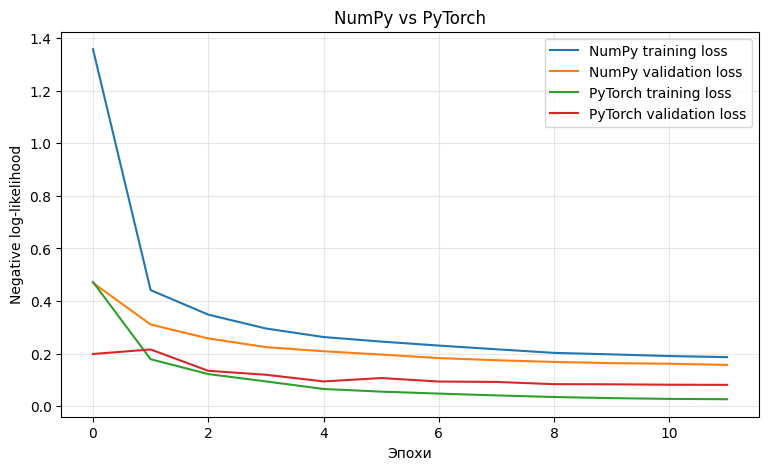

In [62]:
# Your beautiful code here.
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

class TorchNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Linear(784, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.15),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.10),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.layers(x)

X_torch = torch.tensor(X_final, dtype=torch.float32)
y_torch = torch.tensor(np.argmax(Y_final, axis=1), dtype=torch.long)
X_val_torch = torch.tensor(X_val, dtype=torch.float32)
y_val_torch = torch.tensor(y_val, dtype=torch.long)
X_test_torch = torch.tensor(X_test, dtype=torch.float32)
y_test_torch = torch.tensor(y_test, dtype=torch.long)

train_dataset = TensorDataset(X_torch, y_torch)
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
torch_net = TorchNet().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(torch_net.parameters(), lr=1e-3)

n_epoch = 12
torch_history = []

for epoch in range(n_epoch):
    torch_net.train()
    batch_losses = []

    for x_batch, y_batch in train_loader:
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)
        optimizer.zero_grad()
        predictions = torch_net(x_batch)
        loss = criterion(predictions, y_batch)
        loss.backward()
        optimizer.step()
        batch_losses.append(loss.item())

    if (epoch + 1) % 4 == 0:
        for param_group in optimizer.param_groups:
            param_group["lr"] *= 0.5

    torch_net.eval()

    with torch.no_grad():
        val_predictions = torch_net(X_val_torch.to(device))
        val_loss = criterion(val_predictions, y_val_torch.to(device)).item()
        val_accuracy = (val_predictions.argmax(dim=1).cpu() == y_val_torch).float().mean().item()

    torch_history.append((np.mean(batch_losses), val_loss, val_accuracy))
    print("Epoch %2d/%d | train loss %.4f | val loss %.4f | val accuracy %.4f"
    % (epoch + 1, n_epoch, np.mean(batch_losses), val_loss, val_accuracy))

torch_net.eval()

with torch.no_grad():
    test_predictions = torch_net(X_test_torch.to(device))
    test_accuracy = (test_predictions.argmax(dim=1).cpu() == y_test_torch).float().mean().item()

print("PyTorch test accuracy: %.2f%%" % (100 * test_accuracy))

plt.figure(figsize=(9, 5))
plt.plot([x[0] for x in final_history], label="NumPy training loss")
plt.plot([x[1] for x in final_history], label="NumPy validation loss")
plt.plot([x[0] for x in torch_history], label="PyTorch training loss")
plt.plot([x[1] for x in torch_history], label="PyTorch validation loss")
plt.xlabel("Эпохи")
plt.ylabel("Negative log-likelihood")
plt.title("NumPy vs PyTorch")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()